# 12 — The stance panel and its exhibits

**Purpose.** Build the measurement product of Stage 3: legislator stance
records placed on the frozen topic map, aggregated into analysis panels —
and the three exhibits that answer, at a glance, *what was discussed*,
*how attention moved over time*, and *how support and concern divided*.

**Panel definitions.**
- `stance_panel_topic_congress.parquet` — topic × Congress: record counts,
  support/concern counts, net stance = (support − concern)/(support +
  concern), distinct hearings and distinct legislators;
- `stance_panel_legislator.parquet` — bioGuideId × topic × Congress ×
  stance counts (the disaggregated panel later stages estimate on).

Records enter a panel only when placed on a ratified topic (92.6% of
32,385; the rest are the explicit other pool). Congress is the time unit —
the institution's natural cycle and robust cell sizes.

**Figures** (dataviz method: form by job, colors by role — navy = support
pole, red = concern pole, navy-family Blues for magnitude, red↔gray↔navy
diverging for polarity; house layout rules):
1. `fig_stance_topics` — diverging bars, top topics: volume and polarity;
2. `fig_stance_attention` — topic × Congress heatmap of record counts;
3. `fig_stance_net` — same grid, net-stance diverging heatmap (cells with
   fewer than 5 records are blank, not colored).

**Inputs.** `taxonomy/track2_assigned.parquet`, `codebook_v1.parquet` (10).

**Outputs.** two panel parquets in `taxonomy/`; three figure pairs in
`paper/figures/`.

## Build the panels

In [1]:
import json as _json
import os
import sys

sys.path.insert(0, "../lib")

import numpy as np
import pandas as pd

from paths import HF_CACHE, topics_run_dir

os.environ["HF_HOME"] = str(HF_CACHE)
TAX = topics_run_dir("taxonomy")

rec = pd.read_parquet(TAX / "track2_assigned.parquet")
meta = pd.read_parquet(TAX / "codebook_v1.parquet").set_index("topic_id")
rec = rec[rec["topic_id"] >= 0].copy()
rec["congress"] = (rec["year"] - 1787) // 2
rec["theme"] = rec["topic_id"].map(meta["theme_label"])

tp = (rec.groupby(["topic_id", "topic_label", "theme", "congress"])
      .agg(n=("stance", "size"),
           support=("stance", lambda s: (s == "support").sum()),
           concern=("stance", lambda s: (s == "concern").sum()),
           n_hearings=("packageId", "nunique"),
           n_legislators=("bioGuideId", "nunique"))
      .reset_index())
tp["net"] = (tp["support"] - tp["concern"]) / tp["n"]
tp.to_parquet(TAX / "stance_panel_topic_congress.parquet", index=False)

leg = (rec.groupby(["bioGuideId", "surname", "topic_id", "congress",
                    "stance"]).size().rename("n").reset_index())
leg.to_parquet(TAX / "stance_panel_legislator.parquet", index=False)

print(f"records in panel : {len(rec):,} (placed on {rec['topic_id'].nunique()} topics)")
print(f"topic x congress : {len(tp):,} cells, congresses "
      f"{tp['congress'].min()}–{tp['congress'].max()}")
print(f"legislator panel : {len(leg):,} rows, "
      f"{leg['bioGuideId'].nunique():,} legislators")
print(f"overall stance   : support {(rec['stance'] == 'support').mean():.0%} "
      f"/ concern {(rec['stance'] == 'concern').mean():.0%}")

records in panel : 29,979 (placed on 111 topics)
topic x congress : 1,453 cells, congresses 104–119
legislator panel : 15,173 rows, 316 legislators
overall stance   : support 50% / concern 50%


## Figure style (house rules, measured layout)

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from paths import FIGURES

NAVY, RED, GREEN = "#003049", "#A30006", "#7C9885"
CHARCOAL, GRID = "#36454F", "#D0D0D0"
DIVERGE = LinearSegmentedColormap.from_list(
    "stance", [RED, "#f4f2ef", NAVY])   # concern pole, neutral, support pole
sns.set_theme(style="white", font="serif",
              rc={"font.serif": ["DejaVu Serif", "Times New Roman",
                                 "serif"], "font.size": 10,
                  "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                  "ytick.labelsize": 9.5})
NOTE = (f"Note: {len(rec):,} legislator stance records (prompt "
        "stance-extraction-0.3-dev) placed on the frozen Track-1 codebook "
        "v1.0; House Science and Senate Commerce hearings, 106th–119th "
        "Congress (1999–2025). A record is one member position: evidence "
        "sentences, a topic, and support or concern.")
CM_IN = 1 / 2.54

def wrap_to_px(fig, ren, text, width_px, fontsize=8):
    probe = fig.text(0, 0, "", fontsize=fontsize)
    out, curline = [], ""
    for word in text.split():
        trial = f"{curline} {word}".strip()
        probe.set_text(trial)
        if probe.get_window_extent(ren).width <= width_px or not curline:
            curline = trial
        else:
            out.append(curline); curline = word
    out.append(curline); probe.remove()
    return "\n".join(out)

def finish(fig, ax, stem, note, ncol=0, right_x1px=None):
    fig.canvas.draw()
    ren = fig.canvas.get_renderer()
    dpi, W, H = fig.dpi, fig.bbox.width, fig.bbox.height
    gap = 0.3 * CM_IN * dpi
    x0px = ax.yaxis.label.get_window_extent(ren).x0
    x1px = right_x1px if right_x1px is not None else \
        ax.get_window_extent(ren).x1
    xlab_bot = ax.xaxis.label.get_window_extent(ren).y0
    if ncol:
        handles, labels = ax.get_legend_handles_labels()
        leg_ = fig.legend(handles, labels, frameon=False, loc="upper left",
                          bbox_to_anchor=(x0px / W, (xlab_bot - gap) / H),
                          bbox_transform=fig.transFigure, ncol=ncol,
                          fontsize=9, handlelength=1.8, columnspacing=1.4)
        fig.canvas.draw()
        note_top = leg_.get_window_extent(ren).y0 - gap
    else:
        note_top = xlab_bot - gap
    fig.text(x0px / W, note_top / H,
             wrap_to_px(fig, ren, note, x1px - x0px), ha="left", va="top",
             fontsize=8, color="0.35", linespacing=1.4)
    for ext in ("pdf", "svg"):
        fig.savefig(FIGURES / f"{stem}.{ext}", bbox_inches="tight")
    print(f"saved {stem}.pdf/.svg")

## Figure 1 — what was discussed, and how positions divided

Diverging bars for the 25 largest topics: concern records extend left
(red), support records right (navy). Bar length = volume, asymmetry =
polarity — the two questions in one mark.

saved fig_stance_topics.pdf/.svg


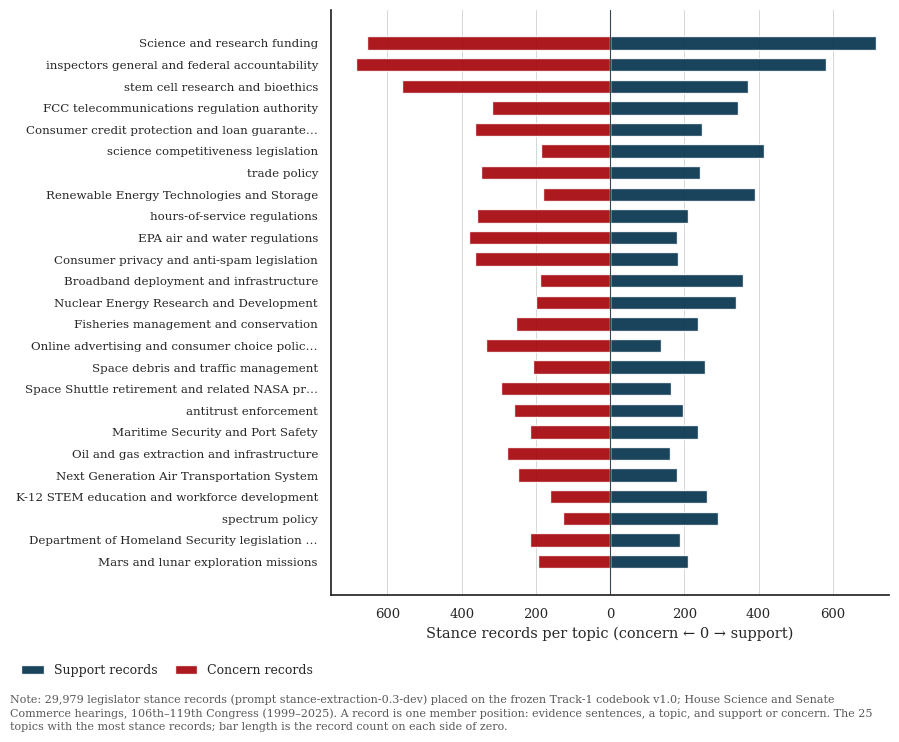

In [3]:
top = (tp.groupby(["topic_id", "topic_label"])[["n", "support",
                                                 "concern"]]
       .sum().nlargest(25, "n").reset_index())
top = top.sort_values("n")

fig, ax = plt.subplots(figsize=(7.2, 7.6))
y = np.arange(len(top))
ax.barh(y, top["support"], height=0.62, color=NAVY, alpha=0.9,
        label="Support records")
ax.barh(y, -top["concern"], height=0.62, color=RED, alpha=0.9,
        label="Concern records")
ax.axvline(0, color=CHARCOAL, lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels([l if len(l) <= 45 else l[:44] + "…"
                    for l in top["topic_label"]], fontsize=8.5)
ax.set_xlabel("Stance records per topic (concern ← 0 → support)")
lim = max(top["support"].max(), top["concern"].max()) * 1.05
ax.set_xlim(-lim, lim)
step = 100 if lim < 600 else 200
ticks = np.arange(-int(lim // step) * step, int(lim // step) * step + 1,
                  step)
ax.set_xticks(ticks)
ax.set_xticklabels([f"{abs(v):,}" for v in ticks])
ax.xaxis.grid(True, color=GRID, linewidth=0.6)
ax.yaxis.grid(False)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
finish(fig, ax, "fig_stance_topics",
       NOTE + " The 25 topics with the most stance records; bar length is "
       "the record count on each side of zero.", ncol=2)

## Figure 2 — attention over time

Topic × Congress heatmap of record counts (sequential Blues — one hue for
one magnitude). Rows are the same 25 topics, largest at top, so this
figure and the next read as one grid.

saved fig_stance_attention.pdf/.svg


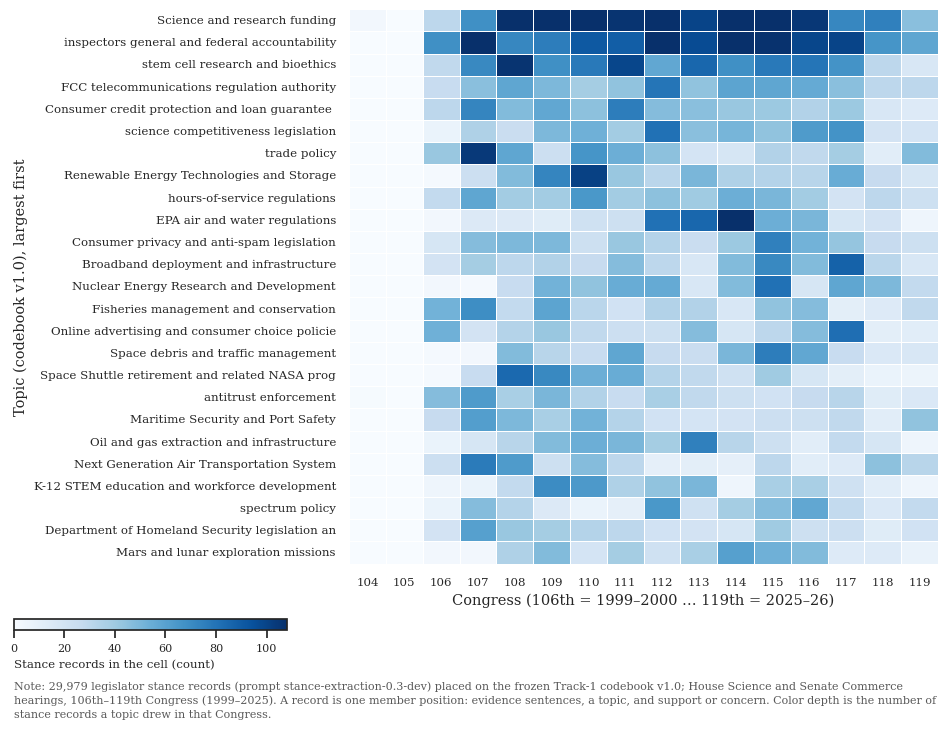

In [4]:
order = top.sort_values("n", ascending=False)
congresses = list(range(int(tp["congress"].min()),
                        int(tp["congress"].max()) + 1))
att = (tp[tp["topic_id"].isin(order["topic_id"])]
       .pivot_table(index="topic_id", columns="congress", values="n",
                    aggfunc="sum", fill_value=0)
       .reindex(order["topic_id"]).reindex(columns=congresses,
                                           fill_value=0))
labels = order.set_index("topic_id")["topic_label"]

fig, ax = plt.subplots(figsize=(7.6, 7.2))
sns.heatmap(att, cmap="Blues", vmax=np.quantile(att.to_numpy(), 0.98),
            cbar=False, linewidths=0.4, linecolor="white", ax=ax)
ax.set_xticks(np.arange(len(congresses)) + 0.5)
ax.set_xticklabels(congresses, rotation=0, fontsize=8.5)
ax.set_yticks(np.arange(len(att)) + 0.5)
ax.set_yticklabels([labels[t][:46] for t in att.index], rotation=0,
                   fontsize=8.5)
ax.set_xlabel("Congress (106th = 1999–2000 … 119th = 2025–26)")
ax.set_ylabel("Topic (codebook v1.0), largest first")
fig.canvas.draw()
ren = fig.canvas.get_renderer()
dpi, W, H = fig.dpi, fig.bbox.width, fig.bbox.height
gap = 0.3 * CM_IN * dpi
x0px = ax.yaxis.label.get_window_extent(ren).x0
x1px = ax.get_window_extent(ren).x1
xlab_bot = ax.xaxis.label.get_window_extent(ren).y0
cb_h = 0.016 * H
cbar_ax = fig.add_axes([x0px / W, (xlab_bot - gap - cb_h) / H, 0.36,
                        cb_h / H])
fig.colorbar(ax.collections[0], cax=cbar_ax, orientation="horizontal",
             label="Stance records in the cell (count)")
cbar_ax.tick_params(labelsize=8)
cbar_ax.xaxis.label.set_size(8.5)
cbar_ax.xaxis.label.set_horizontalalignment('left')
cbar_ax.xaxis.label.set_position((0.0, 0))
fig.canvas.draw()
cb_bot = min(cbar_ax.get_window_extent(ren).y0,
             cbar_ax.xaxis.label.get_window_extent(ren).y0)
fig.text(x0px / W, (cb_bot - gap) / H,
         wrap_to_px(fig, ren, NOTE + " Color depth is the number of "
                    "stance records a topic drew in that Congress.",
                    x1px - x0px), ha="left", va="top", fontsize=8,
         color="0.35", linespacing=1.4)
for ext in ("pdf", "svg"):
    fig.savefig(FIGURES / f"fig_stance_attention.{ext}",
                bbox_inches="tight")
print("saved fig_stance_attention.pdf/.svg")

## Figure 3 — how positions moved

Same grid, now colored by net stance (support − concern as a share of the
cell's records): red = concern-dominant, navy = support-dominant, the
neutral midpoint is gray, and cells with fewer than 5 records stay blank
rather than suggesting a signal that is not there.

saved fig_stance_net.pdf/.svg


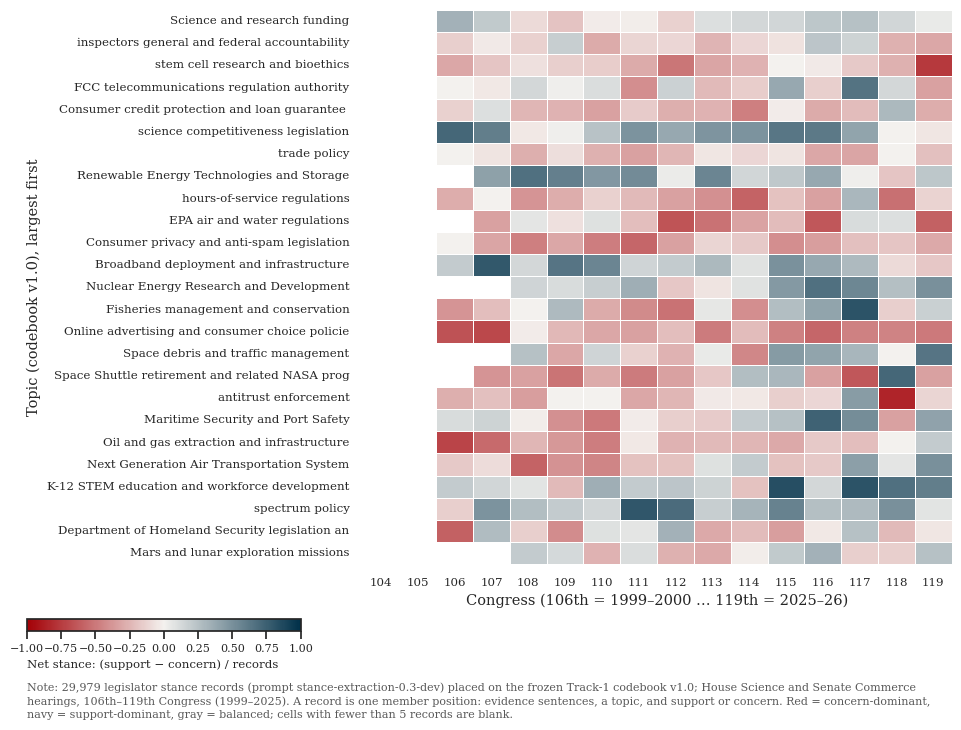

In [5]:
net = (tp[tp["topic_id"].isin(order["topic_id"])]
       .pivot_table(index="topic_id", columns="congress", values="net",
                    aggfunc="mean")
       .reindex(order["topic_id"]).reindex(columns=congresses))
cnt = att.reindex(index=net.index, columns=net.columns)
net = net.where(cnt >= 5)

fig, ax = plt.subplots(figsize=(7.6, 7.2))
sns.heatmap(net, cmap=DIVERGE, vmin=-1, vmax=1, cbar=False,
            linewidths=0.4, linecolor="white", ax=ax)
ax.set_facecolor("white")
ax.set_xticks(np.arange(len(congresses)) + 0.5)
ax.set_xticklabels(congresses, rotation=0, fontsize=8.5)
ax.set_yticks(np.arange(len(net)) + 0.5)
ax.set_yticklabels([labels[t][:46] for t in net.index], rotation=0,
                   fontsize=8.5)
ax.set_xlabel("Congress (106th = 1999–2000 … 119th = 2025–26)")
ax.set_ylabel("Topic (codebook v1.0), largest first")
fig.canvas.draw()
ren = fig.canvas.get_renderer()
dpi, W, H = fig.dpi, fig.bbox.width, fig.bbox.height
gap = 0.3 * CM_IN * dpi
x0px = ax.yaxis.label.get_window_extent(ren).x0
x1px = ax.get_window_extent(ren).x1
xlab_bot = ax.xaxis.label.get_window_extent(ren).y0
cb_h = 0.016 * H
cbar_ax = fig.add_axes([x0px / W, (xlab_bot - gap - cb_h) / H, 0.36,
                        cb_h / H])
fig.colorbar(ax.collections[0], cax=cbar_ax, orientation="horizontal",
             label="Net stance: (support − concern) / records")
cbar_ax.tick_params(labelsize=8)
cbar_ax.xaxis.label.set_size(8.5)
cbar_ax.xaxis.label.set_horizontalalignment('left')
cbar_ax.xaxis.label.set_position((0.0, 0))
fig.canvas.draw()
cb_bot = min(cbar_ax.get_window_extent(ren).y0,
             cbar_ax.xaxis.label.get_window_extent(ren).y0)
fig.text(x0px / W, (cb_bot - gap) / H,
         wrap_to_px(fig, ren, NOTE + " Red = concern-dominant, navy = "
                    "support-dominant, gray = balanced; cells with fewer "
                    "than 5 records are blank.", x1px - x0px),
         ha="left", va="top", fontsize=8, color="0.35", linespacing=1.4)
for ext in ("pdf", "svg"):
    fig.savefig(FIGURES / f"fig_stance_net.{ext}", bbox_inches="tight")
print("saved fig_stance_net.pdf/.svg")

## Verification

In [6]:
back = pd.read_parquet(TAX / "stance_panel_topic_congress.parquet")
assert back["n"].sum() == len(rec)
assert ((back["support"] + back["concern"]) == back["n"]).all()
assert back["net"].between(-1, 1).all()
print(f"1) panel totals reconcile: {back['n'].sum():,} records")
print(f"2) topics in panel: {back['topic_id'].nunique()}, "
      f"congresses {back['congress'].nunique()}")
print(f"3) figures: fig_stance_topics / _attention / _net written")

1) panel totals reconcile: 29,979 records
2) topics in panel: 111, congresses 15
3) figures: fig_stance_topics / _attention / _net written
